**ABOUT DATA SET**


If this Data Set is useful, and upvote is appreciated. This data approach student achievement in secondary education of two Portuguese schools. The data attributes include student grades, demographic, social and school related features) and it was collected by using school reports and questionnaires. Two datasets are provided regarding the performance in two distinct subjects: Mathematics (mat) and Portuguese language (por). In [Cortez and Silva, 2008], the two datasets were modeled under binary/five-level classification and regression tasks. Important note: the target attribute G3 has a strong correlation with attributes G2 and G1. This occurs because G3 is the final year grade (issued at the 3rd period), while G1 and G2 correspond to the 1st and 2nd-period grades. It is more difficult to predict G3 without G2 and G1, but such prediction is much more useful (see paper source for more details).



Student achievement in secondary education of two Portuguese schools.

In [195]:
df=pd.read_csv('/content/student-por-selected-columns.csv')
df.head()

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
0,0,NaN,F,18,U,GT3,A,4,4,at_home,teacher,0,0,1
1,1,NaN,F,17,U,GT3,T,1,1,at_home,other,0,0,1
2,2,NaN,F,15,U,LE3,T,1,1,at_home,other,0,0,1
3,3,NaN,F,15,U,GT3,T,4,2,health,services,0,0,1
4,4,NaN,F,16,U,GT3,T,3,3,other,other,0,0,1


In [196]:
df.head()

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
0,0,NaN,F,18,U,GT3,A,4,4,at_home,teacher,0,0,1
1,1,NaN,F,17,U,GT3,T,1,1,at_home,other,0,0,1
2,2,NaN,F,15,U,LE3,T,1,1,at_home,other,0,0,1
3,3,NaN,F,15,U,GT3,T,4,2,health,services,0,0,1
4,4,NaN,F,16,U,GT3,T,3,3,other,other,0,0,1


In [197]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline


In [198]:
df.shape


(648, 14)

In [199]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 648 entries, 0 to 647
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       648 non-null    int64  
 1   school           0 non-null      float64
 2   sex              648 non-null    object 
 3   age              648 non-null    int64  
 4   address          648 non-null    object 
 5   famsize          648 non-null    object 
 6   Pstatus          648 non-null    object 
 7   Medu             648 non-null    int64  
 8   Fedu             648 non-null    int64  
 9   Mjob             648 non-null    object 
 10  Fjob             648 non-null    object 
 11  sex_encoded      648 non-null    int64  
 12  scl_encoded      648 non-null    int64  
 13  address_encoded  648 non-null    int64  
dtypes: float64(1), int64(7), object(6)
memory usage: 71.0+ KB


In [200]:
df.describe()


,Unnamed: 0,school,age,Medu,Fedu,sex_encoded,scl_encoded,address_encoded
count,648.000000,0.0,648.000000,648.000000,648.000000,648.000000,648.000000,648.000000
mean,323.748457,NaN,16.742284,2.513889,2.307099,0.410494,0.347222,0.697531
std,187.529658,NaN,1.218077,1.135268,1.100714,0.492303,0.476455,0.459682
min,0.000000,NaN,15.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,161.750000,NaN,16.000000,2.000000,1.000000,0.000000,0.000000,0.000000
50%,323.500000,NaN,17.000000,2.000000,2.000000,0.000000,0.000000,1.000000
75%,485.250000,NaN,18.000000,4.000000,3.000000,1.000000,1.000000,1.000000
max,648.000000,NaN,22.000000,4.000000,4.000000,1.000000,1.000000,1.000000


In [201]:
df.isnull().sum()

,0
Unnamed: 0,0
school,648
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0


In [202]:
df.head()

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
0,0,NaN,F,18,U,GT3,A,4,4,at_home,teacher,0,0,1
1,1,NaN,F,17,U,GT3,T,1,1,at_home,other,0,0,1
2,2,NaN,F,15,U,LE3,T,1,1,at_home,other,0,0,1
3,3,NaN,F,15,U,GT3,T,4,2,health,services,0,0,1
4,4,NaN,F,16,U,GT3,T,3,3,other,other,0,0,1


In [203]:
df.tail()

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
643,644,NaN,F,19,R,GT3,T,2,3,services,other,0,1,0
644,645,NaN,F,18,U,LE3,T,3,1,teacher,services,0,1,1
645,646,NaN,F,18,U,GT3,T,1,1,other,other,0,1,1
646,647,NaN,M,17,U,LE3,T,3,1,services,services,1,1,1
647,648,NaN,M,18,R,LE3,T,3,2,services,other,1,1,0


DATA CLEANING

In [204]:
df['school'].unique()

array([nan])

In [205]:
df['Fedu'].astype(int)

,Fedu
0,4
1,1
2,1
3,2
4,3
...,...
643,3
644,1
645,1
646,1


In [209]:
import sklearn

In [210]:
from sklearn.preprocessing import LabelEncoder

In [211]:
le= LabelEncoder()
df['sex_encoded'] = le.fit_transform(df['sex'])
df['sex_encoded']

,sex_encoded
0,0
1,0
2,0
3,0
4,0
...,...
643,0
644,0
645,0
646,1


In [212]:
le= LabelEncoder()
df['scl_encoded'] = le.fit_transform(df['school'])
df['scl_encoded']

,scl_encoded
0,0
1,0
2,0
3,0
4,0
...,...
643,0
644,0
645,0
646,0


In [213]:
le= LabelEncoder()
df['address_encoded'] = le.fit_transform(df['address'])
df['address_encoded']


,address_encoded
0,1
1,1
2,1
3,1
4,1
...,...
643,0
644,1
645,1
646,1


In [215]:
df_copy=df.copy()

In [216]:
df_copy=df_copy.drop(df_copy.index[487])

In [254]:
df_copy[~df_copy['school'].str.isnumeric()]

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded


In [218]:
## Convert Review Datatype to int
df_copy['age']=df_copy['age'].astype(int)

In [219]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 647 entries, 0 to 647
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       647 non-null    int64  
 1   school           0 non-null      float64
 2   sex              647 non-null    object 
 3   age              647 non-null    int64  
 4   address          647 non-null    object 
 5   famsize          647 non-null    object 
 6   Pstatus          647 non-null    object 
 7   Medu             647 non-null    int64  
 8   Fedu             647 non-null    int64  
 9   Mjob             647 non-null    object 
 10  Fjob             647 non-null    object 
 11  sex_encoded      647 non-null    int64  
 12  scl_encoded      647 non-null    int64  
 13  address_encoded  647 non-null    int64  
dtypes: float64(1), int64(7), object(6)
memory usage: 75.8+ KB


In [220]:
df_copy['school'].unique()

array([nan])

In [221]:
df_copy['age'].isnull().sum()

np.int64(0)

In [222]:


# Clean and convert the school column to numeric categories directly
df_copy['school'] = df_copy['school'].map({'GP': 0, 'MS': 1}).astype(float)

In [223]:
df_copy['school']


,school
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
643,NaN
644,NaN
645,NaN
646,NaN


In [224]:
df_copy['Mjob'].unique()


array(['at_home', 'health', 'other', 'services', 'teacher'], dtype=object)

In [225]:
df_copy['sex'].unique()

array(['F', 'M'], dtype=object)

In [226]:
chars_to_remove=['+',',','$']
cols_to_clean=['Mjob','sex']
for item in chars_to_remove:
    for cols in cols_to_clean:
        df_copy[cols]=df_copy[cols].str.replace(item,'')

In [227]:
df_copy['age'].unique()

array([18, 17, 15, 16, 19, 22, 20, 21])

In [228]:
df_copy['Mjob'].unique()

array(['at_home', 'health', 'other', 'services', 'teacher'], dtype=object)

In [229]:
df_copy['age']=df_copy['age'].astype('int')
df_copy['school']=df_copy['school'].astype('string')

In [230]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 647 entries, 0 to 647
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       647 non-null    int64 
 1   school           0 non-null      string
 2   sex              647 non-null    object
 3   age              647 non-null    int64 
 4   address          647 non-null    object
 5   famsize          647 non-null    object
 6   Pstatus          647 non-null    object
 7   Medu             647 non-null    int64 
 8   Fedu             647 non-null    int64 
 9   Mjob             647 non-null    object
 10  Fjob             647 non-null    object
 11  sex_encoded      647 non-null    int64 
 12  scl_encoded      647 non-null    int64 
 13  address_encoded  647 non-null    int64 
dtypes: int64(7), object(6), string(1)
memory usage: 75.8+ KB


In [231]:
## Handlling Last update feature
df_copy['age'].unique()

array([18, 17, 15, 16, 19, 22, 20, 21])

In [232]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 647 entries, 0 to 647
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       647 non-null    int64 
 1   school           0 non-null      string
 2   sex              647 non-null    object
 3   age              647 non-null    int64 
 4   address          647 non-null    object
 5   famsize          647 non-null    object
 6   Pstatus          647 non-null    object
 7   Medu             647 non-null    int64 
 8   Fedu             647 non-null    int64 
 9   Mjob             647 non-null    object
 10  Fjob             647 non-null    object
 11  sex_encoded      647 non-null    int64 
 12  scl_encoded      647 non-null    int64 
 13  address_encoded  647 non-null    int64 
dtypes: int64(7), object(6), string(1)
memory usage: 75.8+ KB


In [233]:
df_copy.head()

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
0,0,<NA>,F,18,U,GT3,A,4,4,at_home,teacher,0,0,1
1,1,<NA>,F,17,U,GT3,T,1,1,at_home,other,0,0,1
2,2,<NA>,F,15,U,LE3,T,1,1,at_home,other,0,0,1
3,3,<NA>,F,15,U,GT3,T,4,2,health,services,0,0,1
4,4,<NA>,F,16,U,GT3,T,3,3,other,other,0,0,1


In [234]:
df_copy.to_csv('/content/student-por-selected-columns.csv')

EDA

In [235]:
df_copy.head()

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
0,0,<NA>,F,18,U,GT3,A,4,4,at_home,teacher,0,0,1
1,1,<NA>,F,17,U,GT3,T,1,1,at_home,other,0,0,1
2,2,<NA>,F,15,U,LE3,T,1,1,at_home,other,0,0,1
3,3,<NA>,F,15,U,GT3,T,4,2,health,services,0,0,1
4,4,<NA>,F,16,U,GT3,T,3,3,other,other,0,0,1


In [236]:
df_copy[df_copy.duplicated('Mjob')].shape

(642, 14)

In [237]:
df_copy=df_copy.drop_duplicates(subset=['Mjob'],keep='first')

In [238]:
df_copy.shape

(5, 14)

EXPLORE DATA

In [239]:
numeric_features = [feature for feature in df_copy.columns if df_copy[feature].dtype != 'O']
categorical_features = [feature for feature in df_copy.columns if df_copy[feature].dtype == 'O']

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 8 numerical features : ['Unnamed: 0', 'school', 'age', 'Medu', 'Fedu', 'sex_encoded', 'scl_encoded', 'address_encoded']

We have 6 categorical features : ['sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob']


## 3.2 Feature Information
1. App :- Name of the App
2. Category :- Category under which the App falls.
3. Rating :- Application's rating on playstore
4. Reviews :- Number of reviews of the App.
5. Size :- Size of the App.
6. Install :- Number of Installs of the App
7. Type :- If the App is free/paid
8. Price :- Price of the app (0 if it is Free)
9. Content Rating :- Appropiate Target Audience of the App.
10. Genres:- Genre under which the App falls.
11. Last Updated :- Date when the App was last updated
12. Current Ver :- Current Version of the Application
13. Android Ver :- Minimum Android Version required to run the App

In [240]:
## Proportion of count data on categorical columns
for col in categorical_features:
    print(df[col].value_counts(normalize=True)*100)
    print('---------------------------')

sex
F    58.950617
M    41.049383
Name: proportion, dtype: float64
---------------------------
address
U    69.753086
R    30.246914
Name: proportion, dtype: float64
---------------------------
famsize
GT3    70.524691
LE3    29.475309
Name: proportion, dtype: float64
---------------------------
Pstatus
T    87.808642
A    12.191358
Name: proportion, dtype: float64
---------------------------
Mjob
other       39.660494
services    20.987654
at_home     20.833333
teacher     11.111111
health       7.407407
Name: proportion, dtype: float64
---------------------------
Fjob
other       56.481481
services    27.932099
at_home      6.481481
teacher      5.555556
health       3.549383
Name: proportion, dtype: float64
---------------------------


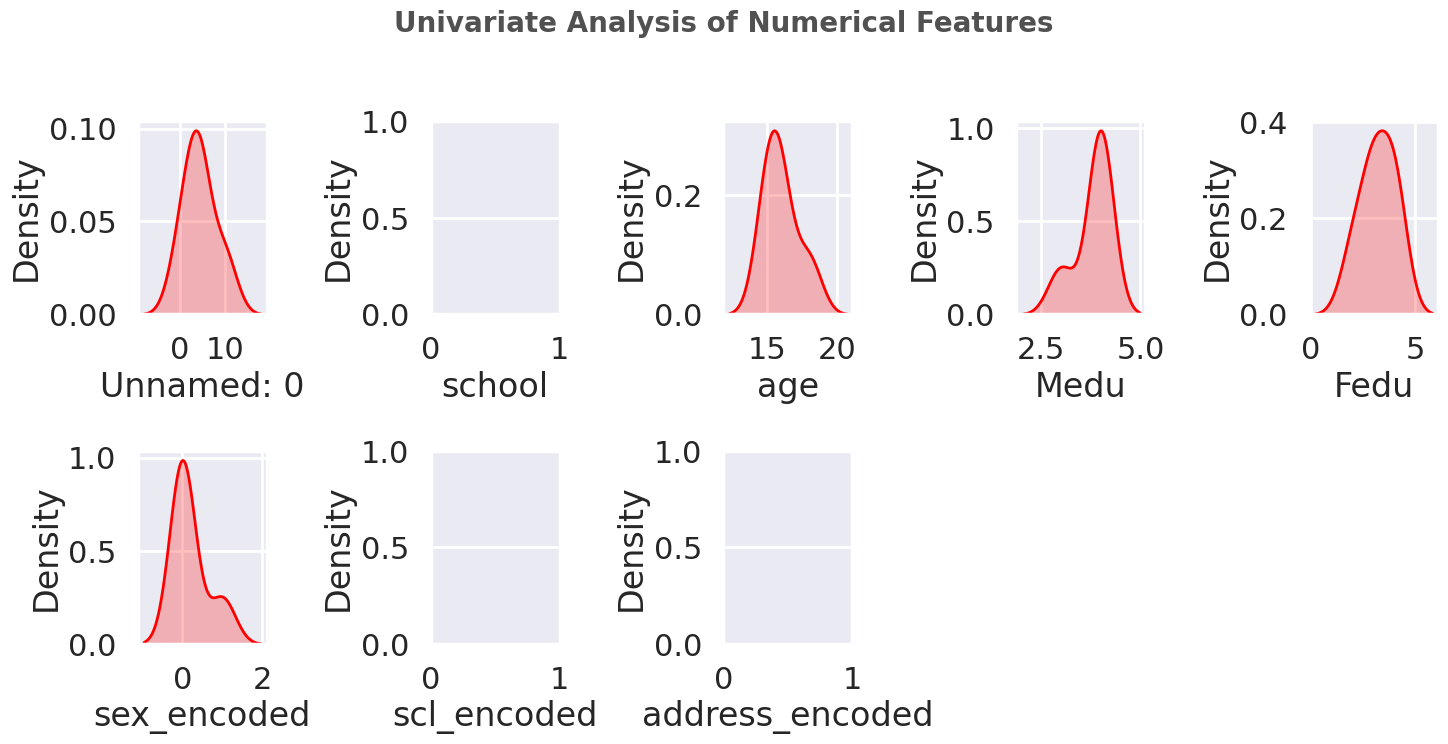

In [241]:
## Proportion of count data on numerical columns
plt.figure(figsize=(15, 10))
plt.suptitle('Univariate Analysis of Numerical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(0, len(numeric_features)):
    plt.subplot(3, 5, i+1)
    sns.kdeplot(x=df_copy[numeric_features[i]],shade=True, color='r')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

## Observations
- Rating and Year is left skewed while Reviews,Size,Installs and Price are right skewed

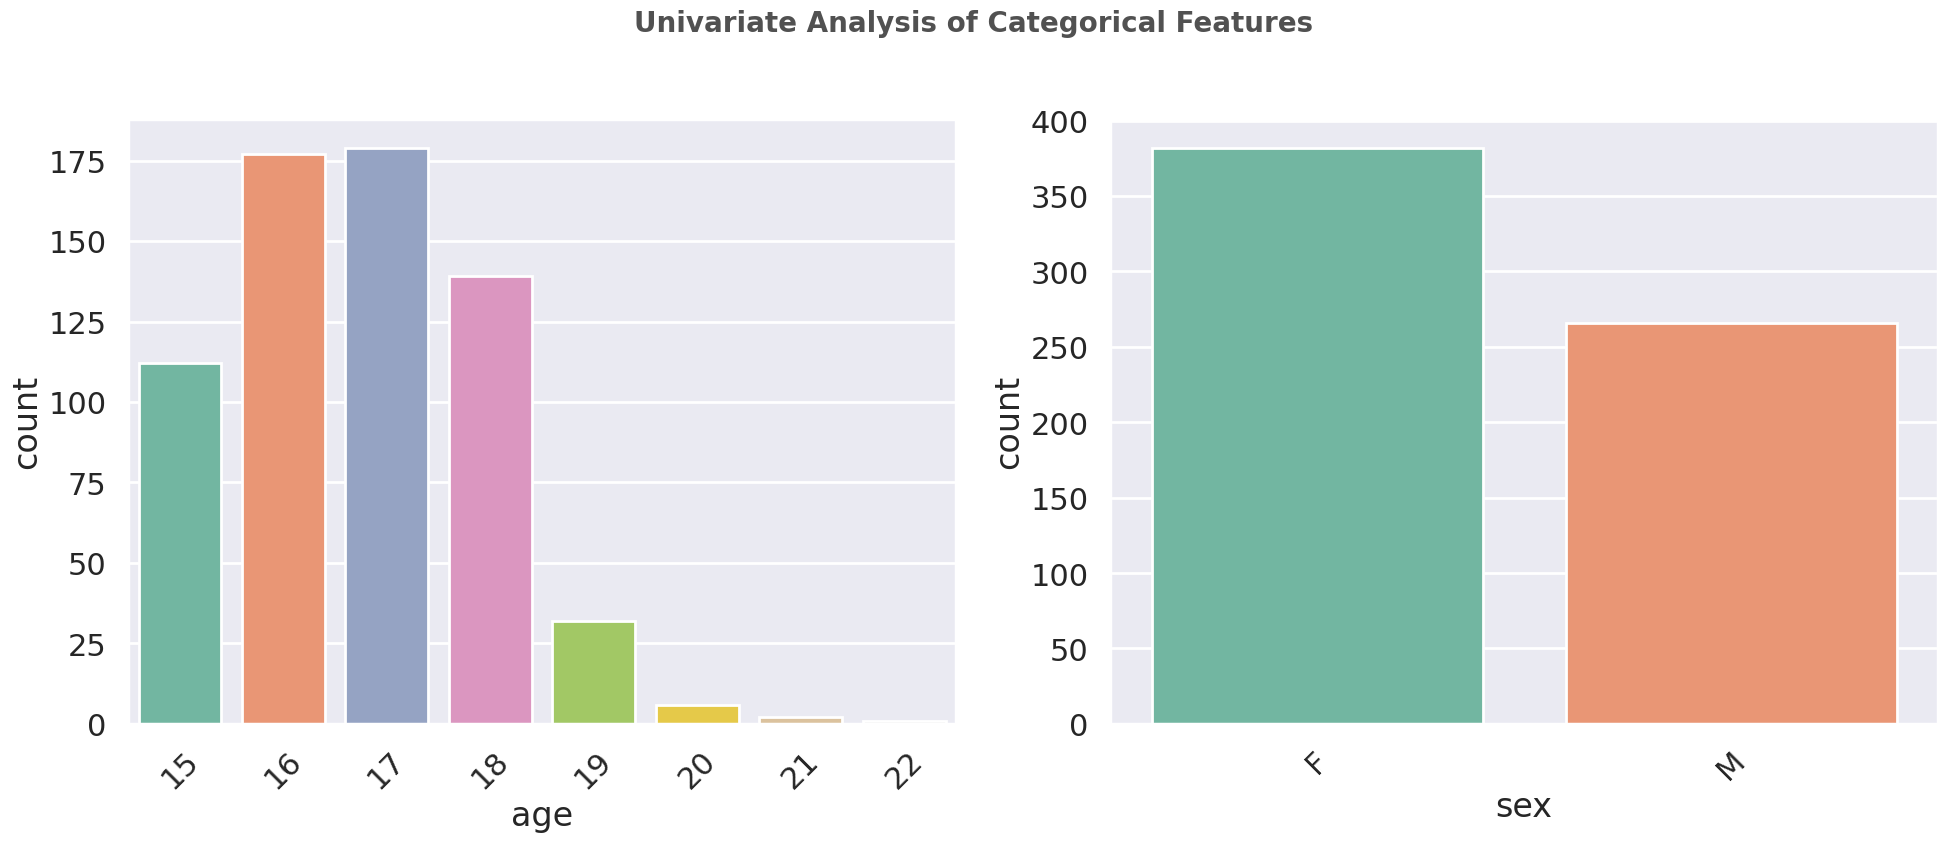

In [242]:
# categorical columns
plt.figure(figsize=(20, 15))
plt.suptitle('Univariate Analysis of Categorical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)
category = [ 'age', 'sex']
for i in range(0, len(category)):
    plt.subplot(2, 2, i+1)
    sns.countplot(x=df[category[i]],palette="Set2")
    plt.xlabel(category[i])
    plt.xticks(rotation=45)
    plt.tight_layout()

## Which is the most popular app category?

In [243]:
df_copy.head(2)

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
0,0,<NA>,F,18,U,GT3,A,4,4,at_home,teacher,0,0,1
3,3,<NA>,F,15,U,GT3,T,4,2,health,services,0,0,1


<Axes: ylabel='count'>

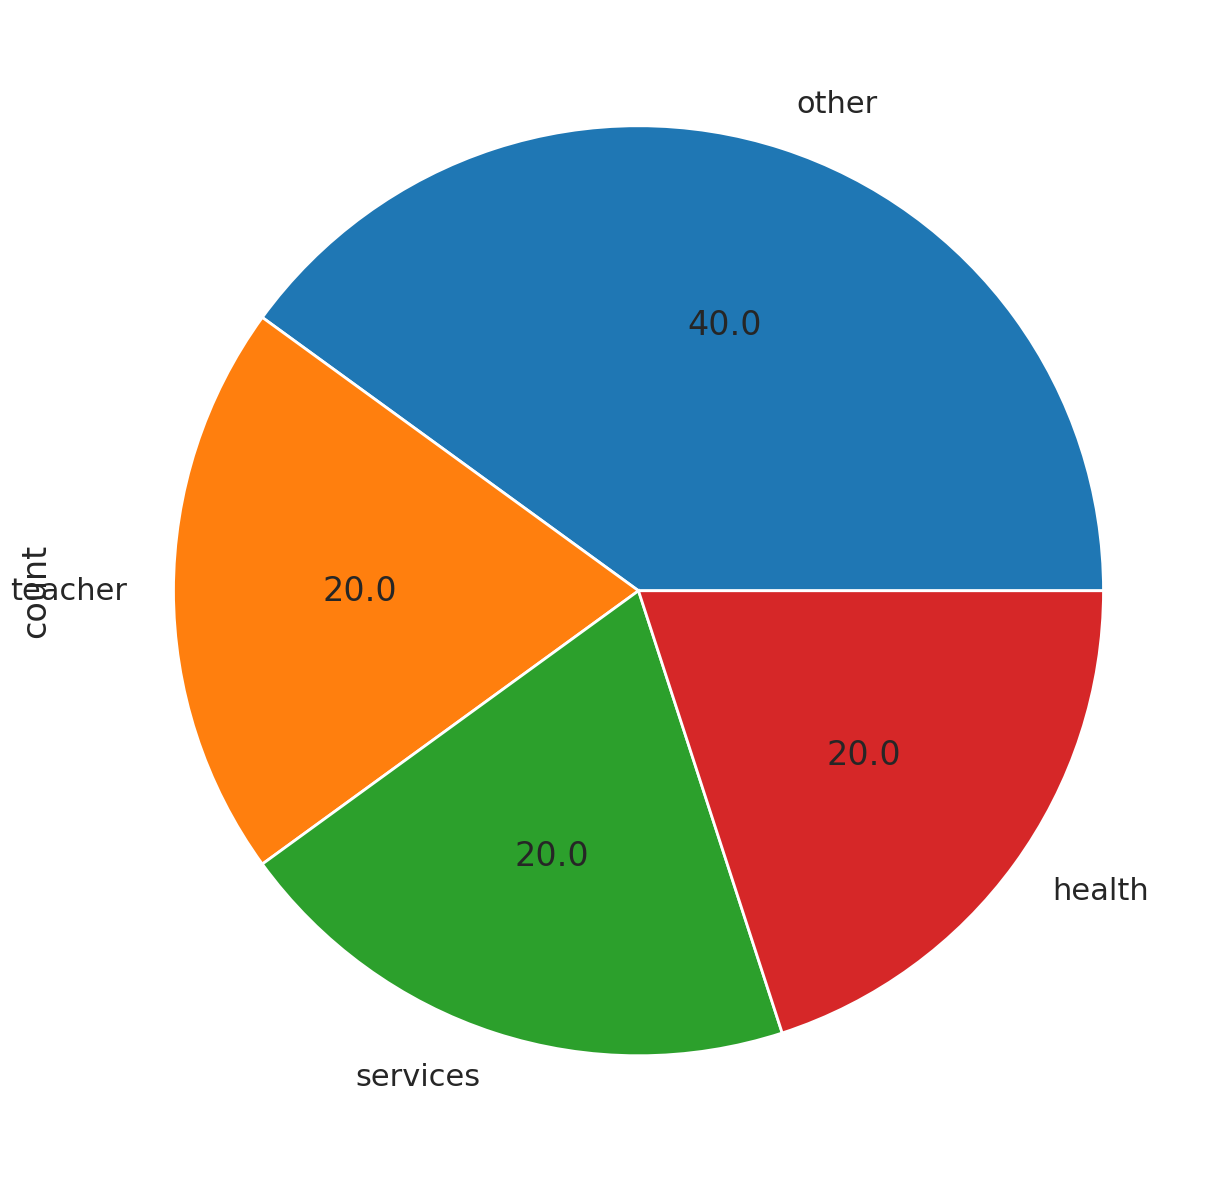

In [244]:
df_copy['Fjob'].value_counts().plot.pie(y=df_copy['Mjob'],figsize=(15,16),autopct='%1.1f')

In [245]:
df

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
0,0,NaN,F,18,U,GT3,A,4,4,at_home,teacher,0,0,1
1,1,NaN,F,17,U,GT3,T,1,1,at_home,other,0,0,1
2,2,NaN,F,15,U,LE3,T,1,1,at_home,other,0,0,1
3,3,NaN,F,15,U,GT3,T,4,2,health,services,0,0,1
4,4,NaN,F,16,U,GT3,T,3,3,other,other,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
643,644,NaN,F,19,R,GT3,T,2,3,services,other,0,0,0
644,645,NaN,F,18,U,LE3,T,3,1,teacher,services,0,0,1
645,646,NaN,F,18,U,GT3,T,1,1,other,other,0,0,1
646,647,NaN,M,17,U,LE3,T,3,1,services,services,1,0,1


## Observations

1. There are more kinds of apps in playstore which are under category of family, games & tools
2. Beatuty,comics,arts and weather kinds of apps are very less in playstore

In [246]:
## Top 10 App Categories
category = pd.DataFrame(df_copy['Mjob'].value_counts())        #Dataframe of apps on the basis of category
category.rename(columns = {'Mjob':'Count'},inplace=True)

category


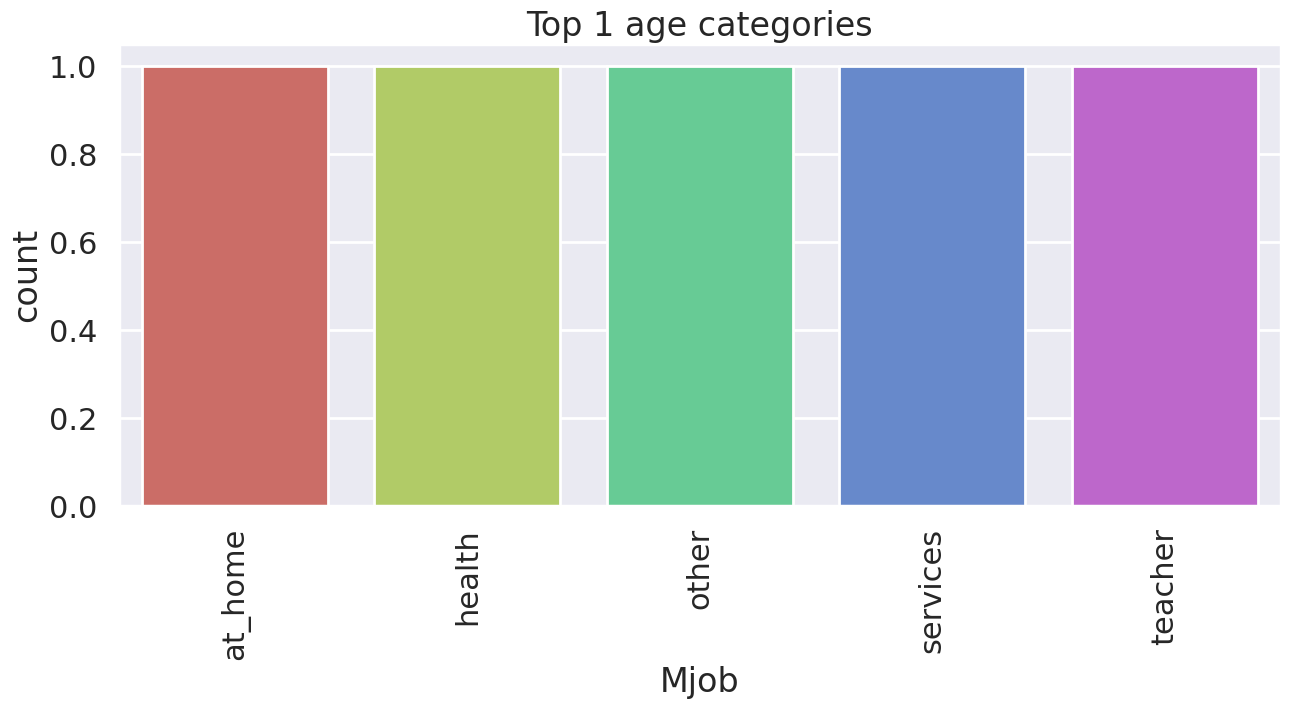

In [247]:
## top 10 app
plt.figure(figsize=(15,6))
sns.barplot(x=category.index[:10], y ='count',data = category[:10],palette='hls')
plt.title('Top 1 age categories')
plt.xticks(rotation=90)
plt.show()

## Insights
1. Family category has the most number of apps with 18% of apps belonging to it, followed by Games category which has 11% of the apps.
2. Least number of apps belong to the Beauty category with less than 1% of the total apps belonging to it.

Text(0.5, 1.0, 'Most Popular age')

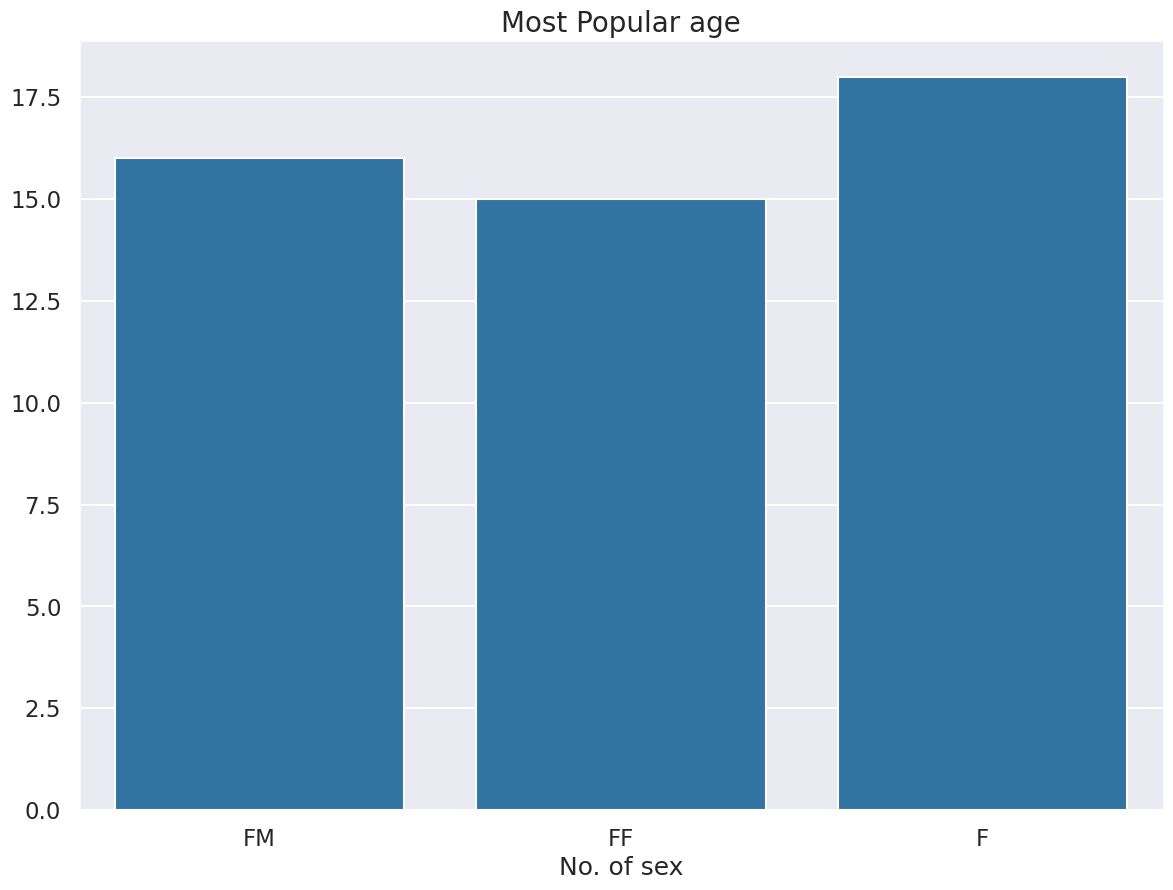

In [248]:
df_cat_sex = df_copy.groupby(['age'])['sex'].sum().sort_values(ascending = False).reset_index()
df_cat_sex.sex = df_cat_sex.sex
df2 = df_cat_sex.head(10)
plt.figure(figsize = (14,10))
sns.set_context("talk")
sns.set_style("darkgrid")

ax = sns.barplot(x = 'sex' , y = 'age' , data = df2 )
ax.set_xlabel('No. of sex')
ax.set_ylabel('')
ax.set_title("Most Popular age", size = 20)

## Insights
1. Out of all the categories "GAME" has the most number of Installations.
2. With almost 35 Billion Installations GAME is the most popular Category in Google App store

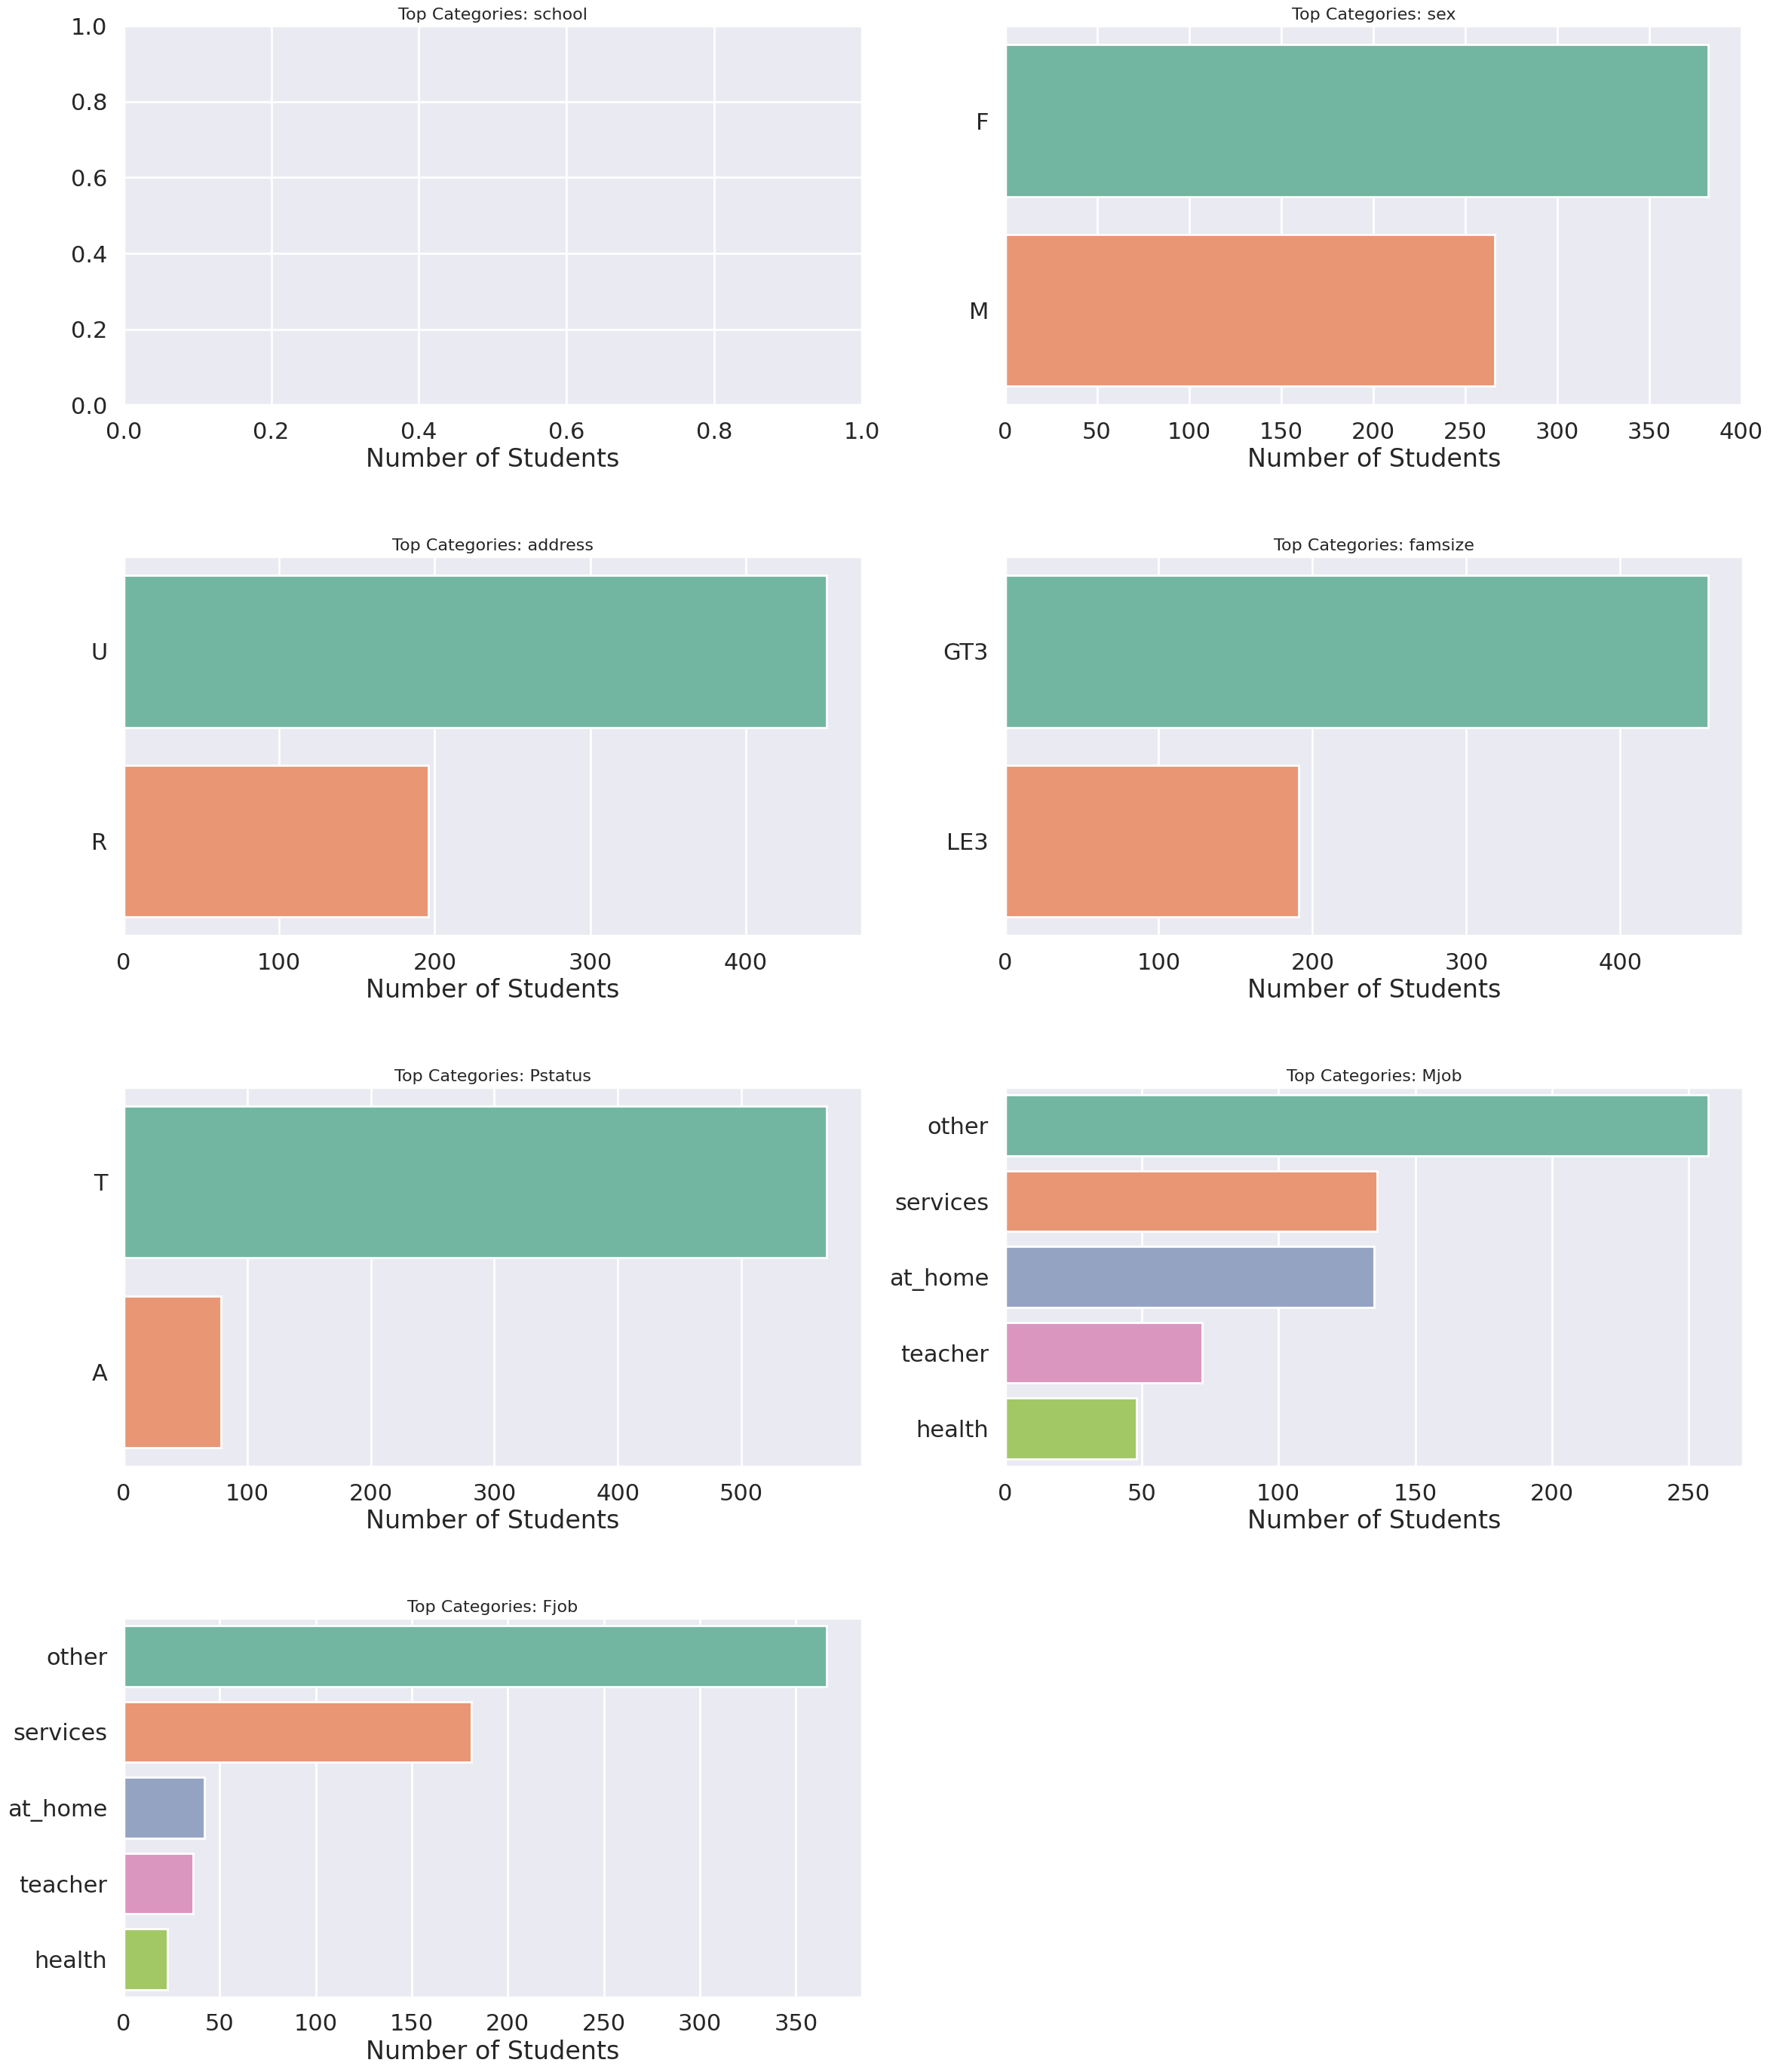

In [249]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Categorical columns in your student dataset
category_cols = [
    'school', 'sex', 'address',
    'famsize', 'Pstatus', 'Mjob', 'Fjob'
]

sns.set_context("poster")
sns.set_style("darkgrid")

plt.figure(figsize=(24, 28))

for i, col in enumerate(category_cols):
    # Count students in each category
    df2 = df[col].value_counts().reset_index()
    df2.columns = [col, 'Student_Count']

    # Select the top 5 categories
    df3 = df2.head(5)

    plt.subplot(4, 2, i + 1)
    sns.barplot(
        data=df3,
        x='Student_Count',
        y=col,
        hue=col,
        palette='Set2',
        legend=False
    )

    plt.xlabel('Number of Students')
    plt.ylabel('')
    plt.title(f'Top Categories: {col}', size=16)

plt.tight_layout()
plt.subplots_adjust(hspace=0.4)
plt.show()


## Insights
- Most popular game is Subway Surfers.
- Most popular communication app is Hangouts.
- Most popular productivity app is Google Drive.
- Most popular social app is Instagram.

## How many apps are there on Google Play Store which get 5 ratings??

In [250]:

# Count students in each age group
rating = (
    df.groupby('age')
      .size()
      .reset_index(name='Student_Count')
      .sort_values('Student_Count', ascending=False)
)

print("Number of age groups:", rating.shape[0])
rating.head(1)


Number of age groups: 8


,age,Student_Count
2,17,179


## Result
- There are 271 five rated apps on Google Play store
- Top most is 'CT Brain Interpretation' from 'Family' Category

In [251]:
df_copy.head()

,Unnamed: 0,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,sex_encoded,scl_encoded,address_encoded
0,0,<NA>,F,18,U,GT3,A,4,4,at_home,teacher,0,0,1
3,3,<NA>,F,15,U,GT3,T,4,2,health,services,0,0,1
4,4,<NA>,F,16,U,GT3,T,3,3,other,other,0,0,1
5,5,<NA>,M,16,U,LE3,T,4,3,services,other,1,0,1
10,10,<NA>,F,15,U,GT3,T,4,4,teacher,health,0,0,1
